## Generating a dataset

Purpose: We want to assess the correlation of structure (e.g. lipophilicity) of some molecules with their inhibitory activity for Acetylcholinesterase (AChE). First of all:

Import dependencies and load the two datasets for activities (ChEMBL) and molecular descriptors (PubChem).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load both datasets
act = pd.read_csv("data/ache_activities.csv")
desc = pd.read_csv("data/ache_pubchem_descriptors.csv")

# Keep only relevant columns from ChEMBL
act = act[["canonical_smiles", "pchembl_value", "standard_relation", "standard_type"]]

# Aggregate (some SMILES might appear multiple times → average or median)
act = act.groupby("canonical_smiles", as_index=False)["pchembl_value"].median()



Inspect the two datasets.

In [2]:
act.head()

,canonical_smiles,pchembl_value
0,Br.CC[N+](CC)(CCCCCn1c(=O)cc(C)n(CCCCCn2c(C)cc...,9.40
1,Br.CC[N+](CC)(CCCCCn1c(=O)cc(C)n(CCCCn2c(C)cc(...,9.22
2,Br.CC[N+](CC)(CCCCCn1c(=O)cc(C)n(CCCn2c(C)cc(=...,8.15
3,Br.COc1ccc2c3c1O[C@H]1C[C@@H](O)C=C[C@@]31CCN(...,5.50
4,Brc1ccc(-[n+]2ccc3ccccc3c2)cc1.[Br-],5.62


In [3]:
desc.head()

,canonical_smiles,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
0,c1ccc(-c2nnc(NCN3CCCCC3)s2)cc1,46889617,274.39,3.3,69.3,1,5,4
1,c1ccc(-c2cnc(NCN3CCCCC3)nn2)cc1,46889618,269.34,2.2,53.9,1,5,4
2,O=C(CCC1CCN(Cc2ccccc2)CC1)c1ccc2c(c1)OCO2,46889660,351.40,4.0,38.8,0,4,6
3,Cc1nc2cc(C(=O)CCC3CCN(Cc4ccccc4)CC3)ccc2[nH]1,10292083,361.50,4.1,49.0,1,3,6
4,Cc1ccc(C(=O)NC(=S)NCCOCCN(C)Cc2ccccc2)cc1,10091498,385.50,3.7,85.7,2,4,9


In [4]:
desc.describe()

,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
count,1.980000e+02,198.000000,177.000000,198.000000,198.000000,198.000000,198.000000
mean,4.949504e+07,400.179343,4.317514,63.947980,1.171717,4.555556,6.287879
std,4.791761e+07,115.507503,1.824386,32.060277,1.042648,1.869999,5.357565
min,1.338000e+03,110.130000,0.100000,0.000000,0.000000,1.000000,0.000000
25%,1.052216e+07,332.650000,2.800000,40.600000,0.000000,3.000000,3.000000
50%,4.433380e+07,392.000000,4.300000,58.850000,1.000000,4.000000,5.000000
75%,7.630799e+07,455.275000,5.300000,84.525000,2.000000,6.000000,9.000000
max,1.646256e+08,801.000000,10.200000,183.000000,5.000000,11.000000,31.000000


In [5]:
act.describe()

,pchembl_value
count,5570.000000
mean,6.132423
std,1.247880
min,4.000000
25%,5.150000
50%,5.970000
75%,7.000000
max,9.920000


In [6]:
desc.info()

<class 'pandas.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   canonical_smiles    198 non-null    str    
 1   CID                 198 non-null    int64  
 2   MolecularWeight     198 non-null    float64
 3   XLogP               177 non-null    float64
 4   TPSA                198 non-null    float64
 5   HBondDonorCount     198 non-null    int64  
 6   HBondAcceptorCount  198 non-null    int64  
 7   RotatableBondCount  198 non-null    int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 22.1 KB


In [7]:
act.info()

<class 'pandas.DataFrame'>
RangeIndex: 5570 entries, 0 to 5569
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   canonical_smiles  5570 non-null   str    
 1   pchembl_value     5570 non-null   float64
dtypes: float64(1), str(1)
memory usage: 374.7 KB


Combine the two datasets.

In [10]:
# Merge on canonical_smiles, how="inner" drops all rows which are only contained in one df
merged = pd.merge(act, desc, on="canonical_smiles", how="inner") 

print(f"Merged dataset: {len(merged)} entries")
merged.head()

Merged dataset: 198 entries


,canonical_smiles,pchembl_value,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
0,C#CCCOC[n+]1ccc(/C=N/O)cc1.[Cl-],4.01,135909812,240.68,NaN,45.7,1,4,5
1,C(=C/C1CCN(Cc2ccccc2)CC1)\c1noc2ccccc12,6.68,9901561,318.40,4.5,29.3,0,3,4
2,C/C=C1\[C@H]2C=C(C)C[C@]1(NC1OCC3=C4CC(C)(C)C[...,6.96,118715261,492.60,1.2,90.8,4,5,2
3,C=CC(=O)N1C/C(=C\c2ccc(C)cc2)C(=O)/C(=C/c2ccc(...,4.74,24796898,357.40,4.4,37.4,0,2,3
4,C=CC(=O)N1C/C(=C\c2ccc(Cl)cc2Cl)C(=O)/C(=C/c2c...,4.80,71720637,467.20,6.2,37.4,0,2,3


Now, inspect the combined dataframe. Look for abnomalies, i.e. duplicates and missing data.

In [12]:
merged[merged.duplicated()]

,canonical_smiles,pchembl_value,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount
63,CCOC(=O)c1c(C)nc2nc3c(c(N)c2c1-c1ccccc1)CCCCCC3,4.770,76318775,389.50,5.3,78.1,1,5,4
71,CC[N+](CC)(CC)CCOc1ccc(C(=O)NCCCCCC(=O)NNc2c3c...,8.120,23657682,691.10,NaN,92.4,4,6,16
93,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,9.520,10765787,446.50,4.4,77.1,1,6,9
108,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,7.750,3152,379.50,4.3,38.8,0,4,6
109,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,7.750,3152,379.50,4.3,38.8,0,4,6
110,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,7.750,3152,379.50,4.3,38.8,0,4,6
111,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,7.750,3152,379.50,4.3,38.8,0,4,6
134,Cc1ccc(F)cc1,6.665,9603,110.13,2.8,0.0,0,1,0
158,Nc1c2c(nc3cc(F)ccc13)CCCC2,7.060,10013554,216.25,2.8,38.9,1,3,0
163,Nc1c2c(nc3ccccc13)CCCC2,6.640,1935,198.26,2.7,38.9,1,2,0


In [13]:
merged.isna().sum()

canonical_smiles       0
pchembl_value          0
CID                    0
MolecularWeight        0
XLogP                 21
TPSA                   0
HBondDonorCount        0
HBondAcceptorCount     0
RotatableBondCount     0
dtype: int64

Decide what to do with the bad data points and proceed. Make sure to document properly and preserve the original dataframe.

In [14]:
# remove duplicates suspected from pubchem query
df_clean = merged.drop_duplicates()

In [17]:
df_clean.shape

(184, 9)

In [19]:
# remove all rows with missing XlogP - only XlogP missing, drop_na()
df_clean.dropna(inplace=True)
df_clean.shape

(164, 9)

Run a quick EDA on the cleaned dataset including some plots. What can you conclude?

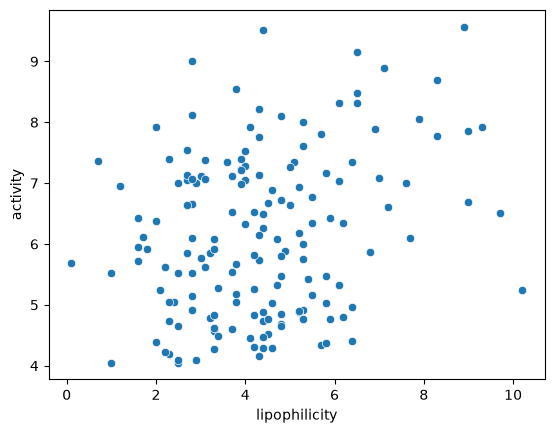

In [20]:
sns.scatterplot(x=df_clean["XLogP"], y=df_clean["pchembl_value"])
plt.xlabel("lipophilicity")
plt.ylabel("activity")
plt.show()

Export the cleaned dataset as "ache_qsar_data.csv".

In [21]:
df_clean.to_csv("data/ache_qsar_data.csv", index=False)